In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [2]:
# 동영상 ID
video_id = "meUpKhUKZ94"

In [3]:
json_path = f'/source/ms/highlight/json/{video_id}.json'

In [4]:
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

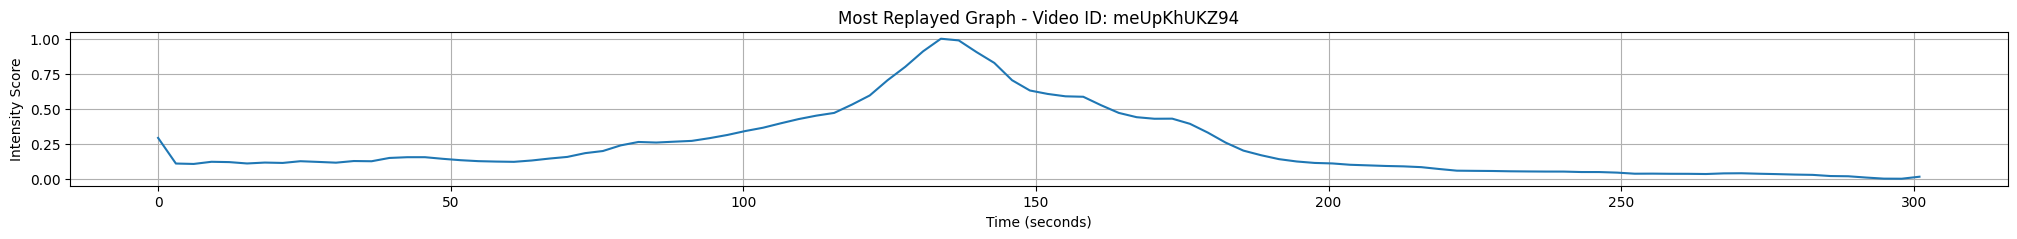

In [5]:



# # API 엔드포인트 URL
# url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# # API 호출하여 JSON 데이터 가져오기
# print('get url!!!')
# response = requests.get(url)
# print('get url finished!!!!!')
# data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


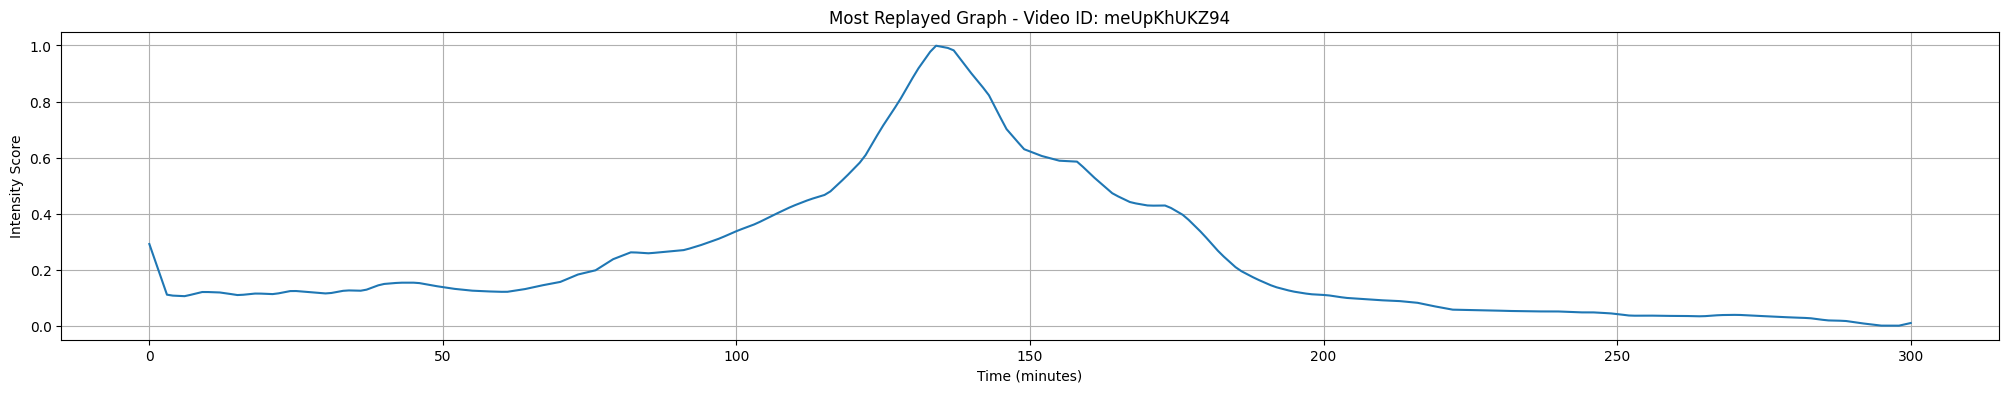

In [8]:
# 보간 함수 생성
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
# plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

# normalize

In [9]:
import numpy as np

def normalize_array(arr):
    min_val = np.min(arr)
    max_val = np.max(arr)
    
    # 0으로 나누는 것을 방지하기 위한 체크
    if max_val == min_val:
        return np.zeros_like(arr)
    
    normalized_arr = (arr - min_val) / (max_val - min_val)
    return normalized_arr

# 정규화 적용
normalized_scores = normalize_array(smoothed_intensity_scores)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


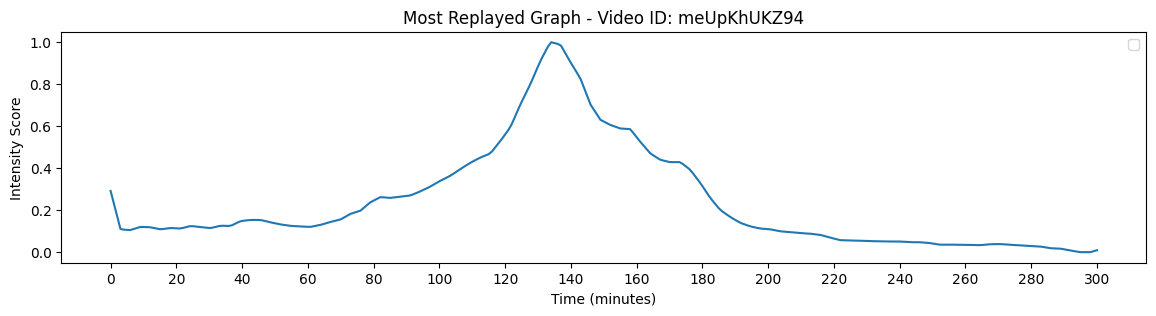

In [13]:
plt.figure(figsize=(14, 3))
plt.plot(new_time, normalized_scores)  # 분으로 변환하여 표시
# plt.plot(np.array(event_lst) , normalized_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_seconds + 1, 20))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# 소리 크기

In [43]:
from moviepy.editor import VideoFileClip
import librosa
import numpy as np
import matplotlib.pyplot as plt

# # 비디오 파일 경로
ROOT = "./song"
video_path = f"{ROOT}/{video_id}.mp4"

# # 비디오에서 오디오 추출
video = VideoFileClip(video_path)
audio = video.audio
audio_path = f"{ROOT}/temp_audio.wav"
audio.write_audiofile(audio_path)



# 임시 오디오 파일 삭제
import os
# os.remove("temp_audio.wav")

MoviePy - Writing audio in ./song/temp_audio.wav


MoviePy - Done.


In [46]:
y, sr = librosa.load(audio_path)


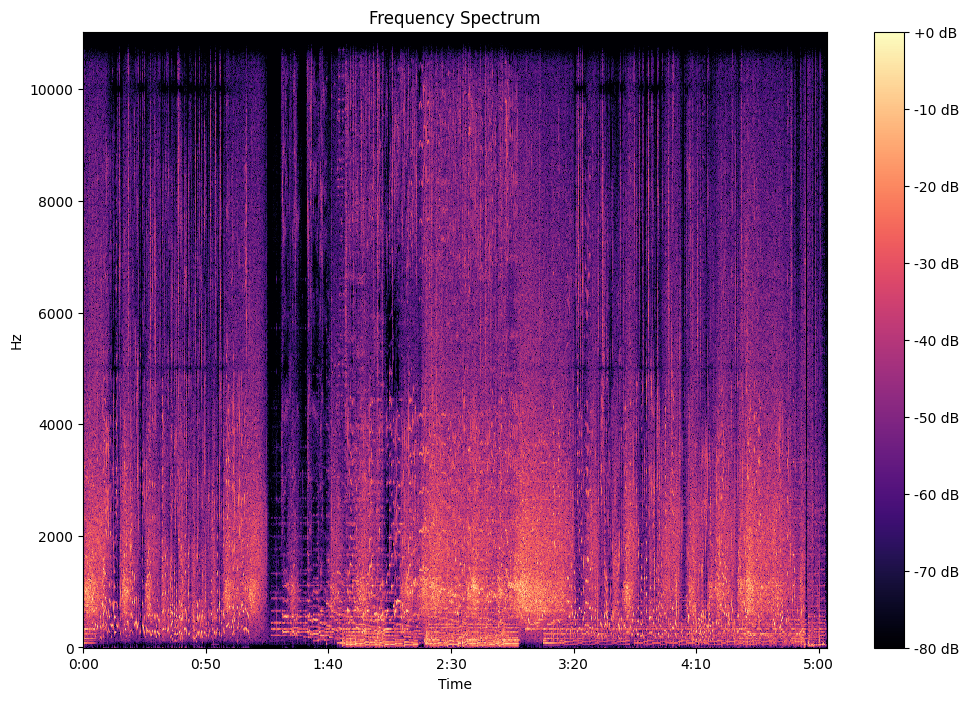

In [47]:
# 푸리에 변환 수행
n_fft = 2048  # FFT 윈도우 크기
D = librosa.stft(y, n_fft=n_fft)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# 스펙트로그램 시각화
plt.figure(figsize=(12, 8))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Frequency Spectrum')
plt.show()

In [45]:
import scipy.signal
import soundfile as sf

low_freq = 500
high_freq = 2500

# 밴드패스 필터 설계
nyquist = 0.5 * sr
low = low_freq / nyquist
high = high_freq / nyquist
b, a = scipy.signal.butter(6, [low, high], btype='band')

# 필터 적용
y_filtered = scipy.signal.lfilter(b, a, y)

# 진폭 임계값 설정 (예: 신호의 RMS 값의 2배)
rms = np.sqrt(np.mean(y_filtered**2))
threshold = 2 * rms

# 임계값을 넘는 부분만 유지
y_extracted = np.where(np.abs(y_filtered) > threshold, y_filtered, 0)

# 결과 저장
sf.write("extracted_cheers.wav", y_extracted, sr)


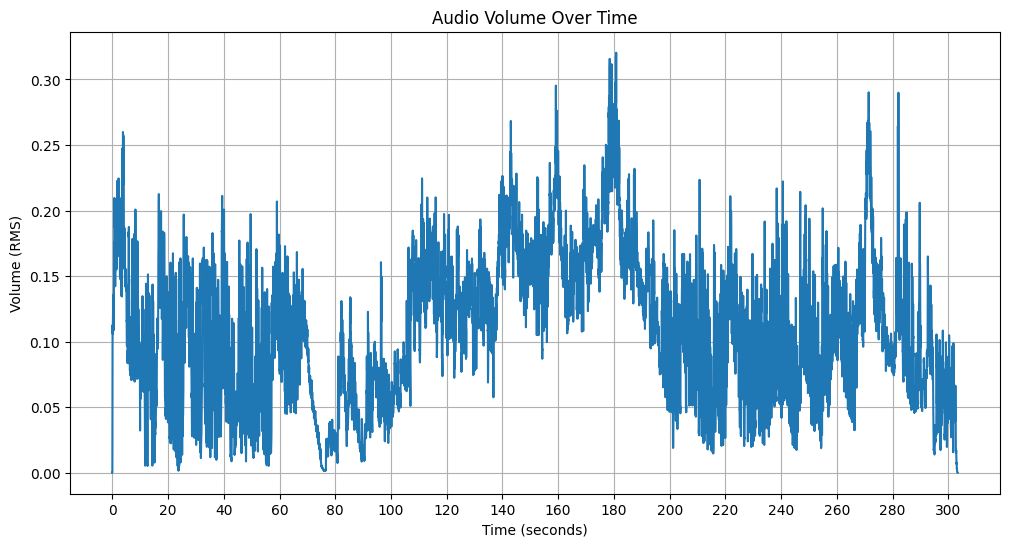

In [17]:
# 오디오 파일 로드
# y, sr = librosa.load("soccer.wav")
y, sr = librosa.load(f"{ROOT}/temp_audio.wav")

# 소리 크기(RMS) 계산
frame_length = int(sr * 0.05)  # 50ms 프레임
hop_length = int(sr * 0.025)  # 25ms 홉
rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)
rms = rms.squeeze()  # 2D에서 1D로 변환

# 시간 배열 생성 (분 단위)
times = librosa.times_like(rms, sr=sr, hop_length=hop_length) 

# 그래프 그리기
plt.figure(figsize=(12, 6))
plt.plot(times, rms)
plt.title("Audio Volume Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Volume (RMS)")
plt.grid(True)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 5, 20))

plt.show()

# smooth

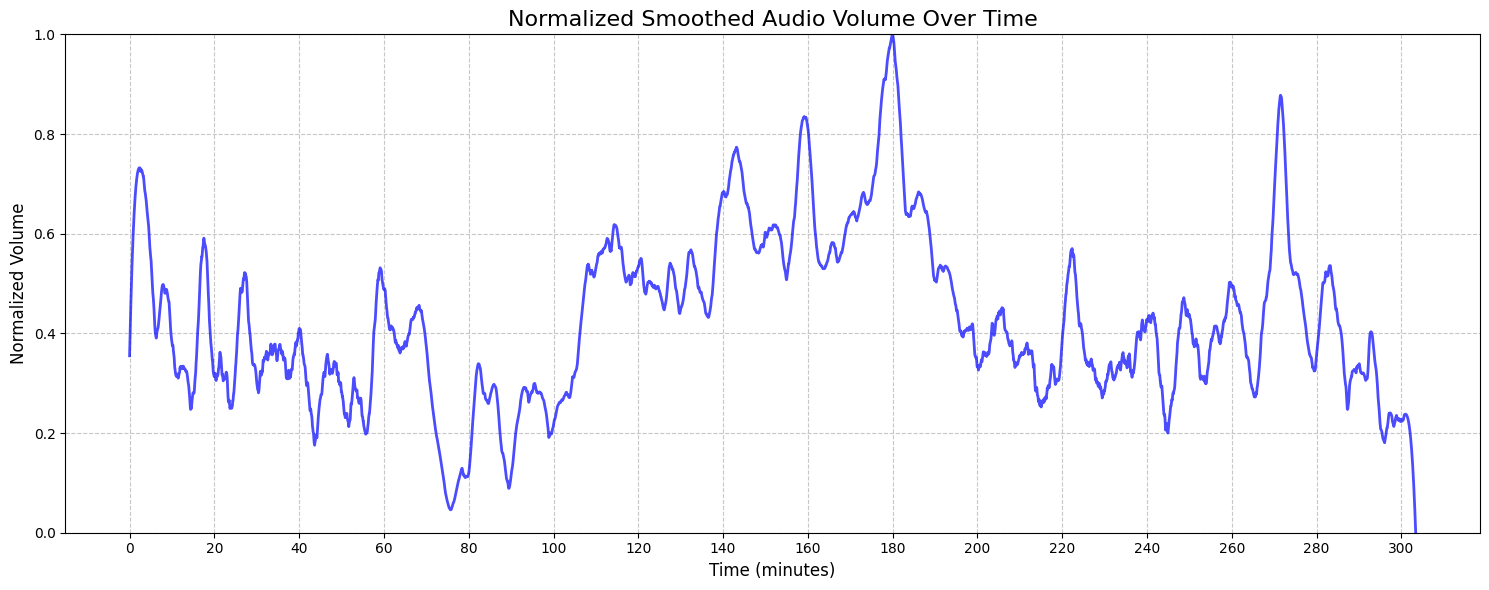

In [35]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import numpy as np

# 이동 평균 적용
window_size = 201  # 윈도우 크기 (홀수여야 함)
smoothed_rms = savgol_filter(rms, window_size, 3)  # Savitzky-Golay 필터 적용

# 0과 1 사이로 정규화
normalized_rms = (smoothed_rms - np.min(smoothed_rms)) / (np.max(smoothed_rms) - np.min(smoothed_rms))

# 그래프 그리기
plt.figure(figsize=(15, 6))
plt.plot(times, normalized_rms, color='blue', alpha=0.7, linewidth=2)
plt.title("Normalized Smoothed Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# y축 범위 설정
plt.ylim(0, 1)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 5, 20))

plt.tight_layout()
plt.show()

# Moving average

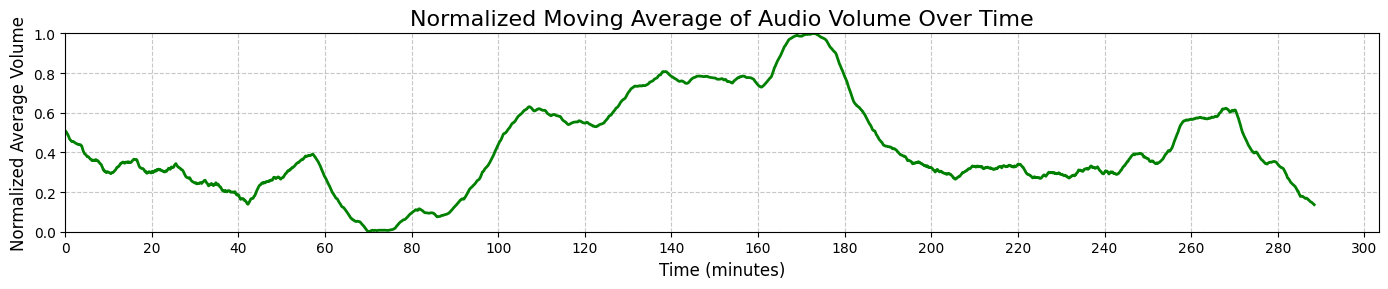

In [31]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size), 'valid') / window_size

def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

window_size = 600  # 조절 가능
ma_rms = moving_average(rms, window_size)

# 0과 1 사이로 정규화
normalized_ma_rms = normalize(ma_rms)

# 결과를 완전히 왼쪽으로 이동
ma_times = times[:len(normalized_ma_rms)]

plt.figure(figsize=(14, 3))
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2)
plt.title("Normalized Moving Average of Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Average Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, max_time + 5, 20))
plt.ylim(0, 1)  # y축 범위를 0에서 1로 설정
plt.xlim(0, max_time)  # x축 범위를 0부터 max_time까지로 설정
plt.tight_layout()
plt.show()

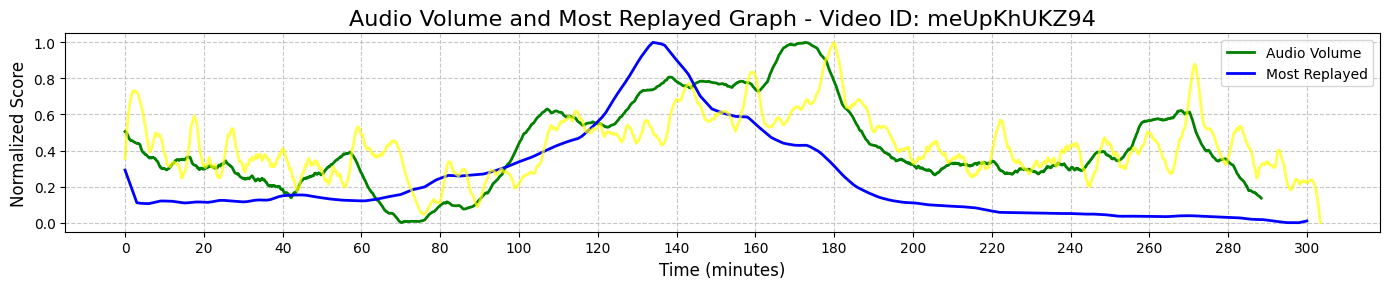

In [42]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time, normalized_scores, color='blue', linewidth=2, label='Most Replayed')
# plt.plot(new_time, normalized_rms, color='blue', linewidth=2, label='Most Replayed')
plt.plot(times, normalized_rms, color='yellow', alpha=0.7, linewidth=2)


# 이벤트 포인트
# plt.plot(np.array(event_lst), normalized_scores[event_lst], "o", color='red', label='Events')
# for group in grouped_points:
#     for i in range(len(group) -1 ):
#         plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)

plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id}', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, total_duration_seconds + 1, 20))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.tight_layout()
plt.show()

# 상관 관계

In [61]:
len(smoothed_intensity_scores)

101

In [62]:
target_scores = normalized_scores

In [63]:
from scipy import interpolate
from scipy import stats


def find_optimal_window_size(window):
    ma_rms = moving_average(rms, window)
    normalized_ma_rms = normalize(ma_rms)
    ma_times = times[:len(normalized_ma_rms)]
    
    if len(normalized_ma_rms) > len(target_scores):
        long_data = normalized_ma_rms
        short_data = target_scores
        long_times = ma_times
        short_times = new_time / 60
    else:
        long_data = target_scores
        short_data = normalized_ma_rms
        long_times = new_time / 60
        short_times = ma_times
    
    f = interpolate.interp1d(short_times, short_data, kind='linear', fill_value='extrapolate')
    resampled_short_data = f(long_times)
    correlation, _ = stats.pearsonr(long_data, resampled_short_data)
    return correlation

In [64]:
max_correlation = -1
optimal_window = 0

for window in range(100, 7000, 100):
    correlation = find_optimal_window_size(window)
    if correlation > max_correlation:
        max_correlation = correlation
        optimal_window = window
    print(f"Window: {window}, Correlation: {correlation}")

print(f"\nOptimal window size: {optimal_window}")
print(f"Maximum correlation: {max_correlation}")

Window: 100, Correlation: 0.2222038975997861
Window: 200, Correlation: 0.2394647740113805
Window: 300, Correlation: 0.25650107283744566
Window: 400, Correlation: 0.27311095813020525
Window: 500, Correlation: 0.28952189226189806
Window: 600, Correlation: 0.305867167525337
Window: 700, Correlation: 0.32207903188816545
Window: 800, Correlation: 0.3378911196966115
Window: 900, Correlation: 0.3532808619126707
Window: 1000, Correlation: 0.36829847945668076
Window: 1100, Correlation: 0.38302202119272605
Window: 1200, Correlation: 0.39746631754062756
Window: 1300, Correlation: 0.4114180879628622
Window: 1400, Correlation: 0.42488847184403233
Window: 1500, Correlation: 0.437900287253448
Window: 1600, Correlation: 0.45041705266496235
Window: 1700, Correlation: 0.46246408958242824
Window: 1800, Correlation: 0.47405837799886014
Window: 1900, Correlation: 0.4851744384566352
Window: 2000, Correlation: 0.4957289341009806
Window: 2100, Correlation: 0.5056899628293025
Window: 2200, Correlation: 0.51497